# 04 — Classification consistency, severity ladder and early signals

**Goal.** Close the gaps left by notebooks 01–03 before we write the cleaning and
modelling code. Each section answers one question that changes a later decision:

| # | Question | Decision it informs |
|---|---|---|
| 1 | Does the symptom recorded at report time match the cause found later? | How much to trust our main early input |
| 2 | Can the data rank events by our priority: life/safety first, then longest, then shorter? | Target definition (severity ladder) |
| 3 | Does *where* an incident happens change its severity? | Location as a model input |
| 4 | Do incidents cluster, and do earlier incidents warn of a severe one? | Recent-history inputs, "earlier escalation" |
| 5 | Is there seasonality in severe events? | Month / season as an input |
| 6 | Has the way delays are recorded changed over the years? | Reporting drift as a limitation |

Scope: **train incidents only**. Parsing is minimal and lives in this notebook for now;
the proper version will be in `code/cleaning/`.

## 0. Setup

In [1]:
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# The notebook lives in code/exploration/; config.py lives in code/.
sys.path.insert(0, str(Path.cwd().parent))
import config

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})

BUCKETS = ["02 min et moins", "03 à 04 min", "05 à 09 min", "10 à 14 min",
           "15 à 19 min", "20 à 24 min", "25 à 29 min", "30 min et plus"]

## 1. Load train incidents and add the helper columns

Every helper below repeats a finding from notebook 01:
* **service date** from the year / month / day-of-month fields (they match the ID 100%)
* **start time** in minutes on the service-day clock (hours can exceed 24)
* **timestamp** = service date + start minutes, so incidents after midnight sort correctly
* **location kind** from simple text rules on `Code de lieu`

In [2]:
incidents = pd.read_csv(config.INCIDENTS_RAW, sep=";", encoding="utf-8-sig",
                        dtype=str, keep_default_na=False)
train = incidents[incidents["Type d'incident"] == "T"].copy()


def to_minutes(hhmm: pd.Series) -> pd.Series:
    # "25:26" or "25:26:00" -> minutes after the start of the service day.
    parts = hhmm.str.split(":", expand=True)
    return parts[0].astype(int) * 60 + parts[1].astype(int)


def location_kind(loc: str) -> str:
    # Same rules as notebook 01, section 8.
    if loc.startswith("Ligne") or loc == "Réseau":
        return "whole line / network"
    if " - Ligne" in loc:
        return "transfer platform"
    if "/" in loc or " - " in loc:
        return "between stations"
    if loc.endswith(" PR"):
        return "PR (ancillary structure)"
    if loc.isupper() or loc.split()[0] in {"Garage", "Arrière", "Centre", "Atelier"}:
        return "yard / shop / facility"
    return "station"


train["bucket"] = pd.Categorical(train["Incident en minutes"], categories=BUCKETS, ordered=True)
train["year"] = train["Année civile"].astype(int)
train["service_date"] = pd.to_datetime(dict(year=train["year"],
                                            month=train["Mois calendrier"].astype(int),
                                            day=train["Jour du mois"].astype(int)))
train["start_min"] = to_minutes(train["Heure de l'incident"])
train["timestamp"] = train["service_date"] + pd.to_timedelta(train["start_min"], unit="min")
train["location_kind"] = train["Code de lieu"].map(location_kind)

# Working targets, as in notebook 03.
train["y_5"] = train["bucket"] >= "05 à 09 min"
train["y_30"] = train["bucket"] == "30 min et plus"

train = train.sort_values("timestamp").reset_index(drop=True)
print(f"Train incidents: {len(train):,}  "
      f"({train['timestamp'].min():%Y-%m-%d} to {train['timestamp'].max():%Y-%m-%d})")

Train incidents: 29,167  (2019-01-01 to 2025-09-30)


## 2. Classification consistency: first symptom vs final cause

The **symptom** is the cause the control centre assigns at the moment of the incident;
the **primary cause** is set after investigation. Four symptoms have a cause with the
same name, so for those we can measure how often the first call is confirmed. This is
also the brief's "classification consistency" question, and it tells us how reliable
our main early input is.

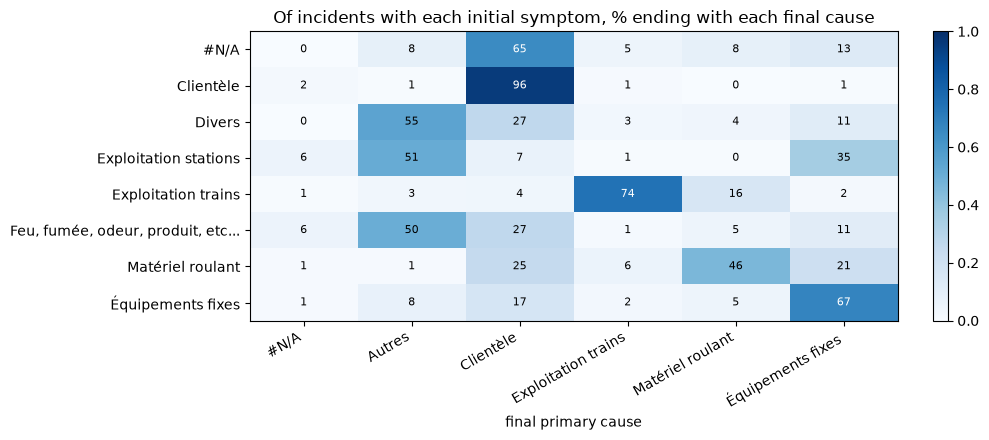

In [3]:
# Row-normalised table: of the incidents with a given symptom, what share ended with each cause?
symptom_vs_cause = pd.crosstab(train["Symptome"], train["Cause primaire"], normalize="index")

fig, ax = plt.subplots(figsize=(10, 4.5))
image = ax.imshow(symptom_vs_cause.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(symptom_vs_cause.shape[1]), symptom_vs_cause.columns, rotation=30, ha="right")
ax.set_yticks(range(symptom_vs_cause.shape[0]), symptom_vs_cause.index)
# Write the percentage in each cell so the reader does not have to guess colours.
for i in range(symptom_vs_cause.shape[0]):
    for j in range(symptom_vs_cause.shape[1]):
        value = symptom_vs_cause.iat[i, j]
        ax.text(j, i, f"{100 * value:.0f}", ha="center", va="center", fontsize=8,
                color="white" if value > 0.6 else "black")
ax.set_xlabel("final primary cause")
ax.set_title("Of incidents with each initial symptom, % ending with each final cause")
ax.grid(False)
fig.colorbar(image, ax=ax, fraction=0.03)
plt.tight_layout()
plt.show()

In [4]:
# Agreement rate for the four symptoms that have a same-named cause, by year.
MATCHING = ["Clientèle", "Matériel roulant", "Équipements fixes", "Exploitation trains"]
comparable = train[train["Symptome"].isin(MATCHING)]
agrees = comparable["Symptome"] == comparable["Cause primaire"]

agreement = (agrees.groupby([comparable["year"], comparable["Symptome"]]).mean()
             .unstack().mul(100).round(1))
agreement["all four"] = (100 * agrees.groupby(comparable["year"]).mean()).round(1)
agreement

Symptome,Clientèle,Exploitation trains,Matériel roulant,Équipements fixes,all four
year,,,,,
2019,95.8,75.1,53.7,74.2,77.3
2020,95.0,69.5,52.5,65.8,75.0
2021,94.5,72.7,52.1,70.5,78.1
2022,96.3,76.7,48.3,65.2,77.0
2023,96.5,73.2,44.3,63.1,76.2
2024,95.8,76.5,28.4,66.6,69.3
2025,95.6,79.1,46.2,64.7,77.2


**Findings.**
* **Customer** symptoms are almost always confirmed (about 96%). Customer incidents are
  easy to recognise on the spot.
* **Rolling stock** symptoms are confirmed less than half the time: about a quarter turn
  out to be customer-caused and a fifth fixed-equipment. "The train has a problem" is a
  first impression, not a diagnosis.
* **Fire / smoke / odour** has no matching cause; half of these end as "Other".
* **Rolling-stock agreement drops to about 28% in 2024**, against 44–54% in every other
  year, while the other symptoms stay stable. Either the 2024 investigations
  reclassified many incidents, or recent causes were still being finalised. Both are
  classification-consistency issues the brief asks about, and 2024 sits inside our
  test period, so we flag it.
* For modelling this is acceptable: we use the symptom as *what the control centre
  knew at the time*, not as the true cause. That is exactly the information an early
  warning system would have.

## 3. A severity ladder: life and safety first, then the longest delays

Our priority order is: **(1) events that put people at risk**, then **(2) the longest
disruptions**, then shorter ones in order. What can the data actually support?

**What the data does *not* have:** any field for injuries, fatalities or a person on the
tracks. The closest signals are:
* `Évacuation`: a car, train or station was evacuated
* `Urgence métro`: the metro emergency team was called in by the control centre
* `Cause secondaire = "Blessée ou malade"` (injured or sick person): set after investigation

These describe the *response* and are only known afterwards. That is fine for a
**target** (we are labelling what happened), but they can never be **inputs**.

First, check whether "injured or sick" marks severe events at all.

In [5]:
injured_or_sick = train["Cause secondaire"].eq("Blessée ou malade")
evacuation = train["Évacuation"].ne("#")
emergency_team = train["Urgence métro"].eq("1")

signals = pd.DataFrame({
    "injured or sick (cause)": injured_or_sick,
    "evacuation": evacuation,
    "emergency team called": emergency_team,
})
pd.DataFrame({
    "incidents": signals.sum(),
    "% lasting 30+ min": [100 * train.loc[signals[c], "y_30"].mean() for c in signals],
    "% lasting 30+ min when flag is off": [100 * train.loc[~signals[c], "y_30"].mean() for c in signals],
}).round(1)

,incidents,% lasting 30+ min,% lasting 30+ min when flag is off
injured or sick (cause),2939,1.5,1.8
evacuation,1371,29.8,0.4
emergency team called,479,44.5,1.1


"Injured or sick" is **not** a severity marker: such incidents are no more likely to be
long than any other (most are a passenger feeling unwell and being helped off).
Evacuation and the emergency team are strongly linked to long delays. So the ladder
uses **evacuation or emergency team** as its safety tier.

**The ladder** (each incident goes into the highest tier it qualifies for):

| Tier | Definition |
|---|---|
| 1. Safety response | evacuation **or** emergency team called |
| 2. Very long | 30+ min, no safety response |
| 3. Long | 10–29 min |
| 4. Moderate | 5–9 min |
| 5. Minor | under 5 min |

In [6]:
safety = evacuation | emergency_team

TIERS = ["1. safety response", "2. 30+ min", "3. 10-29 min", "4. 5-9 min", "5. < 5 min"]
train["tier"] = np.select(
    [safety,
     train["y_30"],
     train["bucket"] >= "10 à 14 min",
     train["y_5"]],
    TIERS[:4],
    default=TIERS[4],
)
train["tier"] = pd.Categorical(train["tier"], categories=TIERS, ordered=True)

ladder = train.groupby("tier", observed=True).agg(incidents=("y_30", "size"))
ladder["% of train incidents"] = (100 * ladder["incidents"] / len(train)).round(2)
ladder["per year"] = (ladder["incidents"] / (train["year"].nunique() - 0.25)).round(0)
# How long are safety-tier incidents? Share of them lasting 30+ min.
ladder.loc[TIERS[0], "% of tier lasting 30+ min"] = round(100 * train.loc[safety, "y_30"].mean(), 1)
ladder

,incidents,% of train incidents,per year,% of tier lasting 30+ min
tier,,,,
1. safety response,1515,5.19,224.0,27.9
2. 30+ min,102,0.35,15.0,NaN
3. 10-29 min,1041,3.57,154.0,NaN
4. 5-9 min,4074,13.97,604.0,NaN
5. < 5 min,22435,76.92,3324.0,NaN


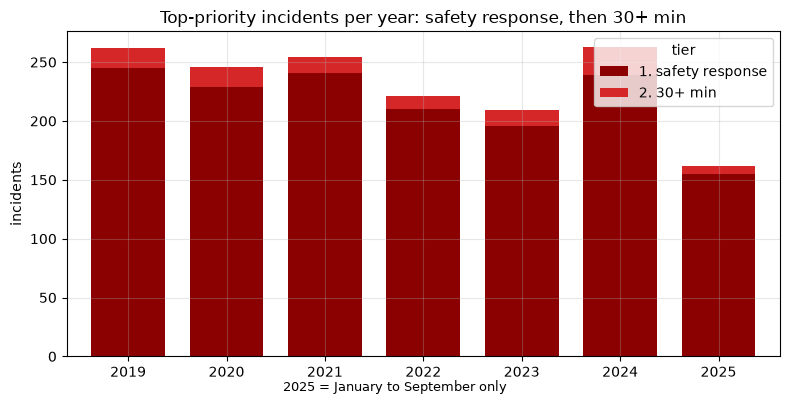

In [7]:
# Plot: tiers 1 and 2 (the top priorities) per year.
top_tiers = (train[train["tier"] <= TIERS[1]]
             .groupby(["year", "tier"], observed=True).size().unstack())

fig, ax = plt.subplots(figsize=(8, 4))
top_tiers.plot.bar(ax=ax, stacked=True, color=["darkred", "tab:red"], width=0.75)
ax.set_title("Top-priority incidents per year: safety response, then 30+ min")
ax.set_xlabel("")
ax.set_ylabel("incidents")
plt.xticks(rotation=0)
fig.text(0.5, 0.01, "2025 = January to September only", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

In [8]:
# Does the symptom (known at report time) separate the two top tiers?
top = train[train["tier"] <= TIERS[1]]
(pd.crosstab(top["Symptome"], top["tier"].cat.remove_unused_categories(), normalize="columns")
   .mul(100).round(1).sort_values(TIERS[0], ascending=False))

tier,1. safety response,2. 30+ min
Symptome,,
Matériel roulant,49.3,2.0
Clientèle,23.2,42.2
"Feu, fumée, odeur, produit, etc...",14.5,10.8
Équipements fixes,10.3,43.1
Exploitation trains,1.8,0.0
Exploitation stations,0.4,0.0
Divers,0.3,2.0
#N/A,0.2,0.0


**Findings.**
* The safety tier has about **1,500 incidents (about 5% of train incidents, roughly 220
  a year)**, about three times the size of the 30+ min group, because many evacuations
  are short (only about 28% of them last 30+ min).
* **"Safety response" is not the same as "danger to life".** About half of the safety
  tier starts with a *rolling stock* symptom: typically a train breaks down and the
  passengers are taken off it. That is an important operational event, but the data
  cannot separate it from a life-threatening one. Fire / smoke is about 15% of the tier.
* After the safety tier takes its share, very few 30+ min events are left over
  (around 100 in total): about 80% of very long delays *are* safety-response events.
* So the ladder is mostly **one big safety tier** plus duration tiers below it. A
  practical target set is: tier 1 as the top-priority label, and 30+ min as the
  "longest disruption" label, then the shorter thresholds for the comparison models.
* The fields behind the safety tier are operational responses, so the tier measures
  *how STM reacted*, which depends partly on procedures. We say that clearly in the README.

## 4. Location and severity

Intuition: a train stuck *between* stations is harder to deal with than one at a
platform (people cannot simply step off), so it should run longer and need evacuations
more often.

In [9]:
by_kind = train.groupby("location_kind").agg(
    incidents=("y_30", "size"),
    pct_5plus=("y_5", "mean"),
    pct_30plus=("y_30", "mean"),
    pct_safety=("tier", lambda s: (s == TIERS[0]).mean()),
)
by_kind[["pct_5plus", "pct_30plus", "pct_safety"]] *= 100
by_kind.sort_values("pct_30plus", ascending=False).round(1)

,incidents,pct_5plus,pct_30plus,pct_safety
location_kind,,,,
whole line / network,294,38.1,18.0,22.8
transfer platform,239,25.9,6.3,9.6
between stations,1960,37.2,4.8,7.4
PR (ancillary structure),392,8.9,2.8,4.1
station,24963,20.9,1.4,4.8
yard / shop / facility,1319,18.9,0.8,4.2


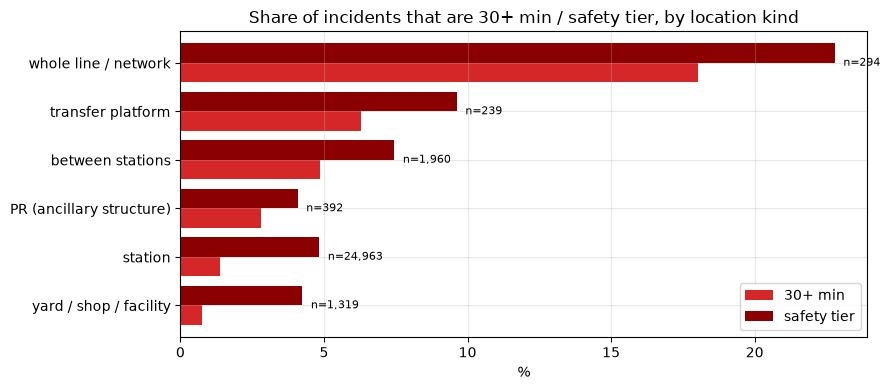

In [10]:
# Plot: severe and safety rates by location kind, with sample sizes.
plot_kind = by_kind.sort_values("pct_30plus")

fig, ax = plt.subplots(figsize=(9, 4))
plot_kind[["pct_30plus", "pct_safety"]].plot.barh(ax=ax, color=["tab:red", "darkred"], width=0.8)
# Sample size to the right of each pair of bars: small groups give noisy rates.
for i, (n, longest) in enumerate(zip(plot_kind["incidents"],
                                     plot_kind[["pct_30plus", "pct_safety"]].max(axis=1))):
    ax.annotate(f"n={n:,}", (longest + 0.3, i), va="center", fontsize=8)
ax.set_title("Share of incidents that are 30+ min / safety tier, by location kind")
ax.set_xlabel("%")
ax.set_ylabel("")
ax.legend(["30+ min", "safety tier"])
plt.tight_layout()
plt.show()

**Findings.**
* **Between stations:** 30+ min about **3.4×** as often as at a station (4.8% vs 1.4%).
  This confirms the intuition and makes location kind a strong early input.
* **Whole line / network** has by far the highest severe rate (about 18%), but caution: a
  location of "the whole line" may be *written down because* the incident ended up
  affecting the whole line. That would make it partly an outcome, not an input. We
  treat it as a possible leak and test the model with and without it.
* Yards, shops and ancillary structures are rarely severe.

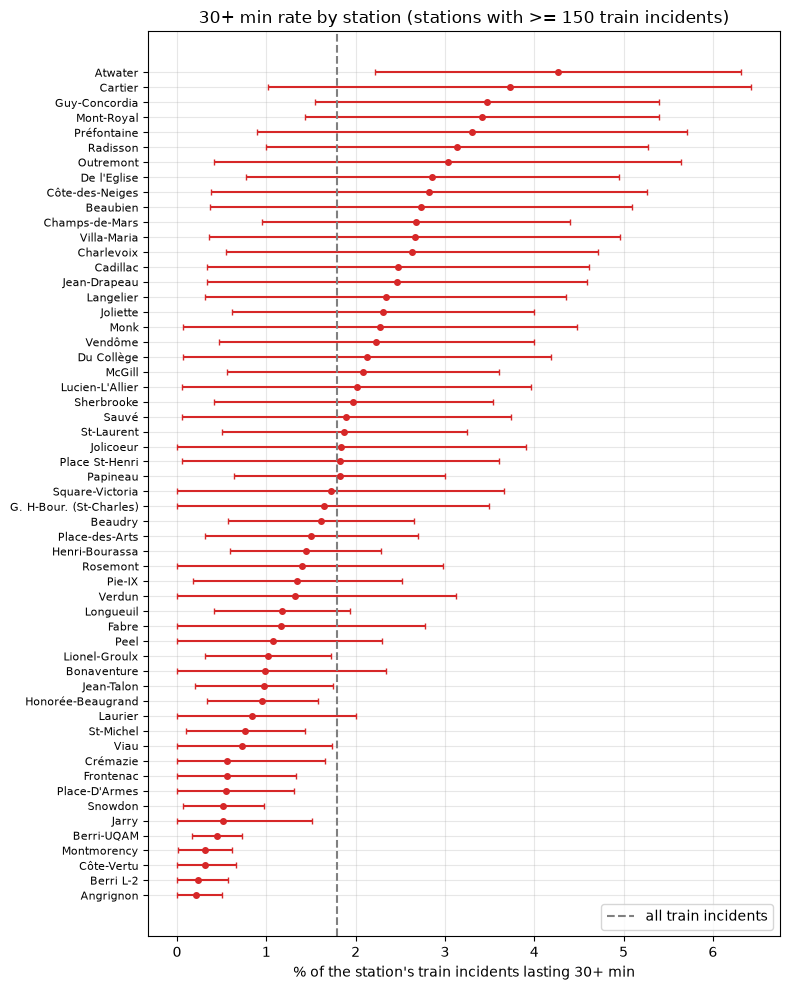

In [11]:
# Station-level view: stations with at least 150 train incidents, ranked by 30+ rate,
# with an approximate 95% interval (normal approximation for a proportion).
stations = train[train["location_kind"] == "station"]
by_station = stations.groupby("Code de lieu").agg(incidents=("y_30", "size"),
                                                  severe=("y_30", "sum"))
by_station = by_station[by_station["incidents"] >= 150].copy()
p = by_station["severe"] / by_station["incidents"]
half_width = 1.96 * np.sqrt(p * (1 - p) / by_station["incidents"])
by_station["% 30+"] = 100 * p
by_station["low"] = 100 * (p - half_width).clip(lower=0)
by_station["high"] = 100 * (p + half_width)
by_station = by_station.sort_values("% 30+")

fig, ax = plt.subplots(figsize=(8, 10))
ax.errorbar(by_station["% 30+"], range(len(by_station)),
            xerr=[by_station["% 30+"] - by_station["low"], by_station["high"] - by_station["% 30+"]],
            fmt="o", color="tab:red", markersize=4, capsize=2)
ax.set_yticks(range(len(by_station)), by_station.index, fontsize=8)
ax.axvline(100 * train["y_30"].mean(), color="gray", linestyle="--", label="all train incidents")
ax.set_title("30+ min rate by station (stations with >= 150 train incidents)")
ax.set_xlabel("% of the station's train incidents lasting 30+ min")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Findings.** Terminal stations (Angrignon, Montmorency, Côte-Vertu, Honoré-Beaugrand)
and the Berri-UQAM hub have **many** incidents but very **few** severe ones: they are where trains turn around
and where many minor customer incidents get handled (e.g. clearing a train). Busy
downtown and interior stations sit higher. Most station-level intervals are wide and
overlap, so the raw station name will be a noisy input. Grouping (terminal vs interior,
transfer vs not) is likely more robust than one category per station.

## 5. Clustering and early signals

The VP Operations wants *earlier* escalation. One way to get it would be if severe
events tended to follow other incidents on the same line (a "bad day" building up).
Two checks: (a) are incidents clustered in time at all? (b) are incidents that follow
recent ones more likely to be severe?

Incidents per line-day: mean 2.91, variance 8.16 (Poisson would have variance = mean)


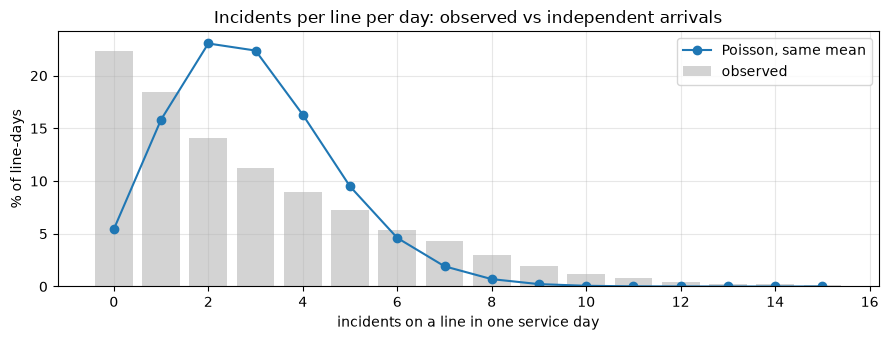

In [12]:
# (a) Incidents per (line, service day) on the four main lines, compared with a Poisson
# distribution of the same mean. Poisson = incidents arriving independently at random.
MAIN_LINES = ["Ligne verte", "Ligne orange", "Ligne jaune", "Ligne bleue"]
main = train[train["Ligne"].isin(MAIN_LINES)]

# Count every (line, day) pair, including days with zero incidents.
all_days = pd.MultiIndex.from_product(
    [MAIN_LINES, pd.date_range(main["service_date"].min(), main["service_date"].max())],
    names=["Ligne", "service_date"])
per_line_day = main.groupby(["Ligne", "service_date"]).size().reindex(all_days, fill_value=0)

mean, variance = per_line_day.mean(), per_line_day.var()
print(f"Incidents per line-day: mean {mean:.2f}, variance {variance:.2f} "
      f"(Poisson would have variance = mean)")

observed = per_line_day.value_counts(normalize=True).sort_index().loc[:15]
poisson = pd.Series([math.exp(-mean) * mean ** k / math.factorial(k) for k in observed.index],
                    index=observed.index)

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(observed.index, 100 * observed, color="lightgray", label="observed")
ax.plot(poisson.index, 100 * poisson, "o-", color="tab:blue", label="Poisson, same mean")
ax.set_title("Incidents per line per day: observed vs independent arrivals")
ax.set_xlabel("incidents on a line in one service day")
ax.set_ylabel("% of line-days")
ax.legend()
plt.tight_layout()
plt.show()

In [13]:
# (b) For each incident, count earlier incidents on the same line in the previous
# 60 minutes and earlier the same service day. Then compare severe rates.
def count_previous(group: pd.DataFrame, window_min: int) -> pd.Series:
    # Number of earlier incidents within `window_min` minutes, on a time-sorted group.
    times = group["timestamp"].to_numpy()
    first_in_window = np.searchsorted(times, times - np.timedelta64(window_min, "m"))
    return pd.Series(np.arange(len(times)) - first_in_window, index=group.index)


train["prev_60min"] = pd.concat(count_previous(g, 60) for _, g in train.groupby("Ligne"))
train["prev_same_day"] = train.groupby(["Ligne", "service_date"]).cumcount()

# Readable group labels (text, so the two blocks do not mix True/False with numbers).
last_hour = np.where(train["prev_60min"] > 0, "yes", "no")
same_day = train["prev_same_day"].clip(upper=5).astype(str).replace("5", "5 or more")

def rates_by(groups) -> pd.DataFrame:
    # Count and severe rates for each group, computed in one pass so rows stay aligned.
    out = train.groupby(groups).agg(incidents=("y_30", "size"),
                                    pct_5plus=("y_5", "mean"),
                                    pct_30plus=("y_30", "mean"))
    out[["pct_5plus", "pct_30plus"]] = (100 * out[["pct_5plus", "pct_30plus"]]).round(2)
    return out


pd.concat({
    "incident on same line in previous 60 min": rates_by(last_hour),
    "earlier incidents on same line, same day": rates_by(same_day),
})

incidents  pct_5plus  pct_30plus
incident on same line in previous 60 min no             22497      22.26        1.89
                                         yes             6670      21.08        1.48
earlier incidents on same line, same day 0               8087      21.45        2.10
                                         1               5857      22.37        1.62
                                         2               4445      21.57        1.51
                                         3               3341      22.15        1.95
                                         4               2458      21.93        1.87
                                         5 or more       4979      22.70        1.63

**Findings.**
* Incidents **are** clustered: line-day counts are almost three times as variable as
  random arrivals would be, with too many quiet days and too many busy days. Busy days exist
  (peak service, events, weather).
* But a busy day does **not** make the *next* incident more likely to be severe: the
  30+ rate after a recent incident is the same or slightly lower. Severe events tend to
  come out of the blue.
* So "recent incidents on the line" is a weak input for the severe target. Earlier
  escalation has to come from **what the incident looks like** (symptom, location,
  door/brake flags), not from what happened before it. That is an honest limit for
  the VP Operations.

## 6. Seasonality of severe events

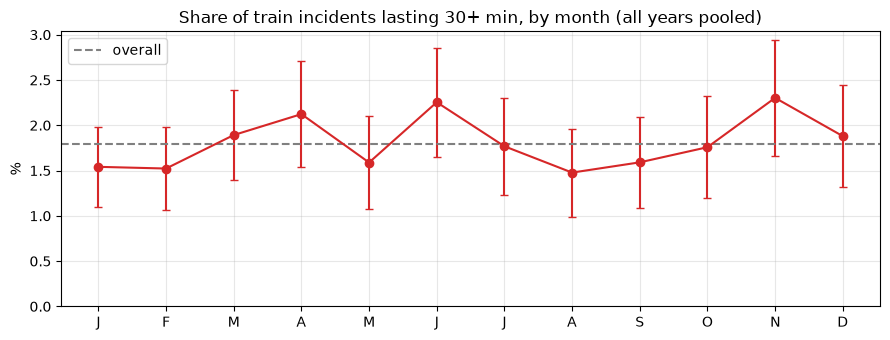

In [14]:
# Severe rate by calendar month of the service date, with an approximate 95% interval.
month = train["service_date"].dt.month
by_month = train.groupby(month).agg(incidents=("y_30", "size"), severe=("y_30", "sum"))
p = by_month["severe"] / by_month["incidents"]
half_width = 1.96 * np.sqrt(p * (1 - p) / by_month["incidents"])

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.errorbar(by_month.index, 100 * p, yerr=100 * half_width, fmt="o-", color="tab:red", capsize=3)
ax.axhline(100 * train["y_30"].mean(), color="gray", linestyle="--", label="overall")
ax.set_xticks(range(1, 13), ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
ax.set_ylim(0, None)
ax.set_title("Share of train incidents lasting 30+ min, by month (all years pooled)")
ax.set_ylabel("%")
ax.legend()
plt.tight_layout()
plt.show()

**Finding.** Monthly severe rates move between about 1.5% and 2.3%, and every
interval overlaps the overall rate. There is **no clear seasonal pattern** in the
*chance* of a severe event. Winter months do have more incidents in total
(notebook 01), so season matters for volume, not for severity.

## 7. Has duration recording changed over time?

Two signs of a shift in reporting practice: (a) the recorded start/end times agree less
often with the official bucket; (b) the mix of buckets moves in a way that suggests a
boundary is being applied differently.

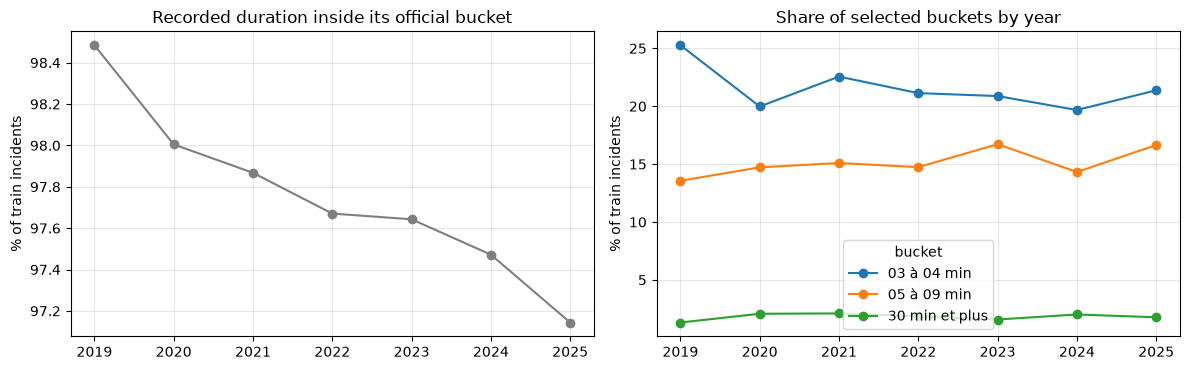

In [15]:
# (a) Share of incidents whose recorded duration falls inside its own bucket.
recorded = to_minutes(train["Heure de reprise"]) - train["start_min"]
BOUNDS = dict(zip(BUCKETS, [(0, 2), (3, 4), (5, 9), (10, 14), (15, 19), (20, 24), (25, 29),
                            (30, np.inf)]))
low = train["Incident en minutes"].map(lambda b: BOUNDS[b][0])
high = train["Incident en minutes"].map(lambda b: BOUNDS[b][1])
inside = recorded.between(low, high)

# (b) Bucket shares by year.
bucket_share = pd.crosstab(train["year"], train["bucket"], normalize="index").mul(100)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
(100 * inside.groupby(train["year"]).mean()).plot(ax=axes[0], marker="o", color="tab:gray")
axes[0].set_title("Recorded duration inside its official bucket")
axes[0].set_ylabel("% of train incidents")
bucket_share[["03 à 04 min", "05 à 09 min", "30 min et plus"]].plot(ax=axes[1], marker="o")
axes[1].set_title("Share of selected buckets by year")
axes[1].set_ylabel("% of train incidents")
for ax in axes:
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

**Findings.**
* Agreement between recorded times and the bucket is high but **falls a little every
  year** (from about 98.5% to about 97%). Small, steady, and in one direction: worth
  mentioning as a reporting-quality signal.
* The 3–4 min share drops after 2019 while the 30+ share rises from 2019 to 2020 and
  stays higher. Part of the 2019 → later difference may be recording practice, not
  reliability. Another reason to train on several years and test on later ones,
  and not to read 2019 as a clean baseline.

## 8. Station incidents as early signals

Station incidents (type `S`) never delay service themselves: they are always in the
shortest delay bucket. But they could still *warn* of train incidents, for example a
crowding or customer problem in a station that then spills onto the platform. If so,
they would be a useful model input or alert trigger.

A raw correlation would mislead here, because busy lines and busy days have more
incidents of **every** kind. So we run three tests, each one controlling for that:
* **(a)** daily counts, compared only within the same line, weekday and month;
* **(b)** train incidents at the same station just *after* a station incident,
  compared with the same station and time of day one and two weeks earlier and later;
* **(c)** as a model input: are train incidents more likely to be major when a station
  incident happened just before them?

This section uses the cleaned data from `code/cleaning/` and the labels from
`code/modeling/target.py`, which were built after sections 1-7. "Major" means
`y_major`: a safety response or a delay of 30+ min.

In [16]:
# Cleaned incidents (reads data/processed/ if saved, otherwise builds it) and labels.
from cleaning.load import load_incidents
from modeling.target import add_targets, model_population

cleaned = load_incidents()
station_incidents = cleaned[cleaned["incident_type"] == "S"]
train_incidents = add_targets(model_population(cleaned))

print(f"Station incidents: {len(station_incidents):,}   train incidents: {len(train_incidents):,}")
station_incidents["symptom"].value_counts()

Station incidents: 16,394   train incidents: 29,167


symptom
Clientèle                             11302
Exploitation stations                  4232
Feu, fumée, odeur, produit, etc...      462
Équipements fixes                        65
Divers                                   39
Name: count, dtype: int64

### 8a. Do station and train incidents move together from day to day?

Count both kinds per line per day (single-line incidents only). The "controlled"
correlations subtract the average of each (line, weekday, month) cell first, so a
green-line Monday in March 2022 is only compared with other green-line Mondays of
that month.

In [17]:
def counts_per_line_day(incidents: pd.DataFrame, column: str = None) -> pd.Series:
    # Number of single-line incidents (or the sum of a yes/no column) per (line, day).
    single_line = incidents[incidents["n_lines"] == 1]
    grouped = single_line.groupby(["line", "service_date"])
    return grouped[column].sum() if column else grouped.size()


all_line_days = pd.MultiIndex.from_product(
    [sorted(train_incidents["line"].dropna().loc[lambda s: ~s.str.contains("\\+")].unique()),
     pd.date_range(cleaned["service_date"].min(), cleaned["service_date"].max())],
    names=["line", "service_date"])
line_days = pd.DataFrame({
    "station": counts_per_line_day(station_incidents),
    "train": counts_per_line_day(train_incidents),
    "major": counts_per_line_day(train_incidents, "y_major"),
}).reindex(all_line_days, fill_value=0).reset_index()

# Remove the (line, weekday, month) average: what is left is "more or less than usual".
cell = [line_days["line"], line_days["service_date"].dt.dayofweek,
        line_days["service_date"].dt.to_period("M")]
usual = line_days.groupby(cell)[["station", "train", "major"]].transform("mean")
residual = line_days[["station", "train", "major"]] - usual
yesterday_station = residual.groupby(line_days["line"])["station"].shift(1)

pd.Series({
    "raw: station vs train": line_days["station"].corr(line_days["train"]),
    "controlled: station vs train": residual["station"].corr(residual["train"]),
    "controlled: station vs major train": residual["station"].corr(residual["major"]),
    "controlled: yesterday's station vs today's train": yesterday_station.corr(residual["train"]),
}, name="correlation").round(3).to_frame()

,correlation
raw: station vs train,0.550
controlled: station vs train,0.087
controlled: station vs major train,0.032
controlled: yesterday's station vs today's train,0.013


**Finding.** The raw correlation (about 0.55) mostly reflects line size: the green
and orange lines carry most passengers and have the most incidents of every kind.
Within the same line, weekday and month it falls to about 0.09, and to almost zero
for major train incidents and for the next day.

### 8b. More train incidents at the same station just after a station incident?

For every station incident, count train incidents at the same station (`station_from`)
in the next 15, 60 and 180 minutes. The **expected** count comes from the same station
and the same time window shifted by -14, -7, +7 and +14 days, which holds the station,
the weekday and the time of day fixed. A ratio of 1 means "no more than usual".
The 95% interval uses the normal approximation on the log scale.

In [18]:
CONTROL_SHIFTS_DAYS = [-14, -7, 7, 14]
WINDOWS_MIN = [15, 60, 180]


def start_times_by_station(incidents: pd.DataFrame) -> dict:
    # Sorted start times of the incidents at each station.
    return {station: np.sort(group.to_numpy())
            for station, group in incidents.groupby("station_from")["start_at"]}


def count_between(sorted_times: np.ndarray, starts: np.ndarray, window_min: int) -> int:
    # Total number of events in the windows (start, start + window], summed over starts.
    ends = starts + np.timedelta64(window_min, "m")
    return int((np.searchsorted(sorted_times, ends, side="right")
                - np.searchsorted(sorted_times, starts, side="right")).sum())


def after_station_incidents(triggers: pd.DataFrame, targets: pd.DataFrame) -> pd.DataFrame:
    # Observed vs time-matched expected counts of `targets` after each trigger.
    target_times = start_times_by_station(targets)
    rows = []
    for window in WINDOWS_MIN:
        observed = control = 0
        for station, group in triggers.groupby("station_from"):
            times = target_times.get(station, np.array([], dtype="datetime64[us]"))
            starts = group["start_at"].to_numpy()
            observed += count_between(times, starts, window)
            control += sum(count_between(times, starts + np.timedelta64(days, "D"), window)
                           for days in CONTROL_SHIFTS_DAYS)
        expected = control / len(CONTROL_SHIFTS_DAYS)
        ratio = observed / expected
        half_width = 1.96 * np.sqrt(1 / observed + 1 / control)
        rows.append({"window (min)": window, "observed": observed, "expected": round(expected, 1),
                     "ratio": ratio, "low": ratio * np.exp(-half_width),
                     "high": ratio * np.exp(half_width)})
    return pd.DataFrame(rows).round(2)


at_a_station = station_incidents[station_incidents["station_from"].notna()]
train_at_a_station = train_incidents[train_incidents["station_from"].notna()]

after = pd.concat({
    "all train incidents": after_station_incidents(at_a_station, train_at_a_station),
    "major train incidents": after_station_incidents(
        at_a_station, train_at_a_station[train_at_a_station["y_major"]]),
})
after

window (min)  observed  expected  ratio   low  high
all train incidents   0            15        74      65.8   1.13  0.87  1.46
                      1            60       285     254.8   1.12  0.98  1.28
                      2           180       795     723.5   1.10  1.02  1.19
major train incidents 0            15         6       2.8   2.18  0.81  5.90
                      1            60        18      10.8   1.67  0.97  2.90
                      2           180        38      29.5   1.29  0.89  1.86

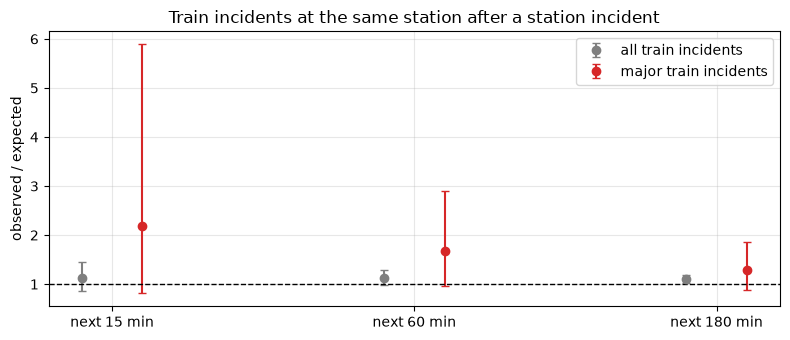

In [19]:
# Plot: observed / expected ratio with its 95% interval, for each window.
fig, ax = plt.subplots(figsize=(8, 3.5))
for offset, (label, colour) in zip([-0.1, 0.1], [("all train incidents", "tab:gray"),
                                                 ("major train incidents", "tab:red")]):
    rows = after.loc[label]
    x = np.arange(len(rows)) + offset
    ax.errorbar(x, rows["ratio"], yerr=[rows["ratio"] - rows["low"], rows["high"] - rows["ratio"]],
                fmt="o", capsize=3, color=colour, label=label)
ax.axhline(1, color="black", linewidth=1, linestyle="--")
ax.set_xticks(range(len(WINDOWS_MIN)), [f"next {w} min" for w in WINDOWS_MIN])
ax.set_ylabel("observed / expected")
ax.set_title("Train incidents at the same station after a station incident")
ax.legend()
plt.tight_layout()
plt.show()

In [20]:
# The same test by symptom of the station incident (all train incidents).
pd.concat({
    symptom: after_station_incidents(at_a_station[at_a_station["symptom"] == symptom],
                                     train_at_a_station)
    for symptom in ["Clientèle", "Exploitation stations", "Feu, fumée, odeur, produit, etc..."]
})

window (min)  observed  expected  ratio   low   high
Clientèle                          0            15        65      56.0   1.16  0.88   1.53
                                   1            60       241     209.0   1.15  1.00   1.33
                                   2           180       659     580.2   1.14  1.04   1.24
Exploitation stations              0            15         3       7.0   0.43  0.13   1.41
                                   1            60        32      33.8   0.95  0.64   1.39
                                   2           180       103     107.2   0.96  0.77   1.19
Feu, fumée, odeur, produit, etc... 0            15         5       1.0   5.00  1.34  18.62
                                   1            60         6       6.8   0.89  0.37   2.15
                                   2           180        18      19.0   0.95  0.57   1.58

**Findings.**
* After a station incident, train incidents at the same station are only about **10%
  more frequent** than usual.
* The ratio for **major** incidents looks larger, but it rests on tiny counts (18
  observed against about 11 expected in the next hour). Across about 16,000 station
  incidents that is about **7 extra major incidents in almost 7 years, roughly one a
  year**, against about 240 major incidents a year. None of the major-incident
  intervals clearly excludes 1.
* Only fire / smoke stands out (5 train incidents in the next 15 minutes against 1
  expected). That is most likely **one event recorded twice** (smoke in a station, trains
  held), not an early warning.

### 8c. As a model input: does a recent station incident make a train incident more severe?

This is how a station incident would enter the classifier: when a train incident is
reported, was there a station incident shortly before it, at the same station or on
the same line? Compare major rates with and without one (Wilson 95% intervals).

In [21]:
def wilson_interval(successes: int, trials: int) -> tuple[float, float]:
    # 95% Wilson interval for a proportion, in %.
    z, p = 1.96, successes / trials
    centre = (p + z**2 / (2 * trials)) / (1 + z**2 / trials)
    half = z * np.sqrt(p * (1 - p) / trials + z**2 / (4 * trials**2)) / (1 + z**2 / trials)
    return 100 * (centre - half), 100 * (centre + half)


def had_recent_event(event_times: dict, keys: pd.Series, starts: pd.Series, window_min: int) -> np.ndarray:
    # For each train incident: was there an event with the same key in the window before it?
    flags = np.zeros(len(keys), dtype=bool)
    for key, positions in keys.groupby(keys).indices.items():
        times = event_times.get(key)
        if times is None:
            continue
        ends = starts.to_numpy()[positions]
        begins = ends - np.timedelta64(window_min, "m")
        flags[positions] = (np.searchsorted(times, ends, side="left")
                            > np.searchsorted(times, begins, side="left"))
    return flags


# Station incidents by station, and by every line they involve.
by_station = start_times_by_station(at_a_station)
station_lines = station_incidents.dropna(subset=["line"]).assign(
    line=lambda df: df["line"].str.split("+")).explode("line")
by_line = {line: np.sort(group.to_numpy())
           for line, group in station_lines.groupby("line")["start_at"]}

rows = []
for window in [30, 60, 180]:
    for scope, events, keys in [
        ("same station", by_station, train_incidents["station_from"]),
        ("same line", by_line, train_incidents["line"].str.split("+").str[0]),
    ]:
        recent = had_recent_event(events, keys, train_incidents["start_at"], window)
        for answer, mask in [("yes", recent), ("no", ~recent)]:
            major = train_incidents.loc[mask, "y_major"]
            low, high = wilson_interval(major.sum(), len(major))
            rows.append({"window (min)": window, "scope": scope, "station incident before": answer,
                         "train incidents": len(major), "% major": 100 * major.mean(),
                         "low": low, "high": high})

pd.DataFrame(rows).set_index(["window (min)", "scope", "station incident before"]).round(2)

train incidents  % major   low   high
window (min) scope        station incident before                                       
30           same station yes                                  141     7.80  4.41  13.43
                          no                                 29026     5.53  5.28   5.80
             same line    yes                                 1741     5.86  4.85   7.06
                          no                                 27426     5.52  5.26   5.80
60           same station yes                                  281     6.05  3.81   9.47
                          no                                 28886     5.54  5.28   5.81
             same line    yes                                 3395     5.45  4.73   6.26
                          no                                 25772     5.56  5.28   5.84
180          same station yes                                  766     4.44  3.19   6.14
                          no                                 28401     5.57  5.31   5.85
             same line    yes                                 8264     5.40  4.93   5.91
                          no                                 20903     5.60  5.30   5.92

**Findings.**
* With and without a recent station incident, the major rate is about the same (around
  5.5%) and the intervals overlap almost completely. The same-station rate even moves
  in both directions depending on the window (higher over 30 minutes, lower over 180).
* Only about 1% of train incidents have a same-station station incident in the hour
  before, so even a real effect would barely move a model.

**Decision.** Station incidents are **not** used as model inputs or alert triggers. This
matches section 5: incidents cluster in time, but earlier incidents do not raise the
severe risk. There is also a timing risk: the data does not say whether station
incidents are logged in real time, and using ones entered after the fact would leak
future information. (Written up as Finding 1 in `documentation.md`.)

## 9. Summary: decisions for cleaning and modelling

| Topic | Finding | Decision |
|---|---|---|
| Symptom vs cause | Customer symptoms ~96% confirmed; rolling stock < 50%, and only ~28% in 2024 | Use symptom as "what was known at report time", not as the true cause; flag the 2024 shift |
| Severity ladder | No injury / fatality field; "injured or sick" is not a severity marker; evacuation or emergency team ≈ 5% of train incidents, half of them train breakdowns, and contains ~80% of 30+ min events | Top-priority target = safety tier; next = 30+ min; then shorter thresholds; state that "safety response" ≠ "danger to life" |
| Location | Between stations ≈ 3.4× the severe rate of stations; terminals low; "whole line" may be recorded after the fact | Use location kind + station group as inputs; test "whole line" as a possible leak |
| Early signals | Incidents cluster, but earlier incidents do not raise severe risk | Recent-history inputs are low priority; say so to VP Operations |
| Seasonality | No clear seasonal pattern in severe *rates* | Month is optional; keep it simple |
| Station incidents | Correlated with train incidents only through volume; no more major train incidents after them (about 1 extra a year); no change in the major rate of the next train incident | Not a model input or alert trigger |
| Recording drift | Small steady drop in time/bucket agreement; bucket mix shifts after 2019 | Note as a limitation; validate on later years |